<a href="https://colab.research.google.com/github/sirnaet/BaristaBot_AI/blob/main/BaristaBot_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ICS 3202: Artificial Intelligence
## Semester Project: ICS 3B
### AI-Based Coffee Recommender Application
**Group Four**

**Group Members**
- Paulette Mbaika - 190016
- Brian Sanaet - 189718
- Stacy Njoki - 160077

**AI Application:** Coffee Recommender Application(mobile application with an ML engine)
**Algorithm/Approach:** Unsupervised learning, K-Means clustering, with similarity-based recommendation


## Summary

Choosing a drink at a busy coffee bar is harder than it looks. We surveyed a barista at the Strathmore University coffee bar (Nairobi, 21 September 2026), who told us that verbal recommendations take time when there are many customers and some are still unsure what to order. The main cost is unhappy customers, and those in a rush are the most affected. Research on choice difficulty supports this: extensive choice can reduce motivation to choose and satisfaction with the choice (Iyengar & Lepper, 2000).

Our project asks whether an AI, taste-based mobile recommender can match customers to drinks they are satisfied with, compared with barista advice. A customer states their tastes (for example sweetness, milk, strength), the ML engine ranks the menu against them, and the suggestion appears on their phone while they are still in the queue.

This notebook builds the ML engine. K-Means groups drinks with similar taste profiles. A similarity measure then ranks the drinks closest to the customer's stated tastes. The notebook follows the CRISP-DM process. It covers every CRISP-DM phase for the ML module, from Business Understanding to the export that the mobile app loads.


## Phase 1: Business Understanding

**1.1 Business objectives**
- Help customers choose a drink faster and with more confidence.
- Reduce the time baristas spend giving verbal recommendations at peak hours.
- Leave customers satisfied with the drink they ordered.

**1.2 Situation assessment**
- *Stakeholder:* a barista at the Strathmore University coffee bar (Industry pillar of the QuadHelix).
- *Who is affected:* time-pressed customers, especially students in a rush, and the staff advising them.
- *Alternatives considered and not chosen:* menu redesign (static, no personalisation), staff training (does not scale at peak hours), a static quiz or flowchart (fixed rules, cannot take free-text tastes), and a generic coffee chatbot (no preference profile or local menu).
- *Out of scope:* payments and POS integration, inventory forecasting, rollout across multiple shops, and health or nutrition advice.
- *Key risk:* a mismatch between the recommended drink and what the customer actually wants.

**1.3 Problem statement**
Customers at university coffee bars struggle to choose drinks quickly, and it is unknown how well an AI, taste-based mobile recommender can match them to satisfying drinks compared with barista advice.

**1.4 Data mining goals**
- Group drinks (and coffees) into clusters with similar taste profiles, using K-Means.
- Take a customer's stated tastes and return the closest matching drinks, ranked by similarity.
- Support optional filters (hot or iced, no milk, caffeine limit) so suggestions fit the customer's needs.

**1.5 Success criteria for the ML engine**
- Clusters are well separated and meaningful, checked with the elbow method and the silhouette score.
- Recommendations behave as expected on sanity checks, for example 'strong, no milk' returns espresso-style drinks.
- Comparison against other clustering models is future work. Customer satisfaction against barista advice is tested after deployment.

**1.6 Project plan**
Business Understanding, Data Understanding, Data Preparation, Modelling, Evaluation, Deployment (the mobile app).


## Phase 2: Data Understanding

**2.1 Data collected**
We worked with two datasets:

| Dataset | Rows | Description |
| --- | --- | --- |
| `coffee_clean.csv` | 2,440 | Coffee reviews (the `slug` column links to coffeereview.com). 20 columns, including roaster, origin, roast, price and a rating (80-98). Five taste scores (aroma, acid, body, flavor, aftertaste) run from 5 or 6 to 10. |
| `coffee_drinks.csv` | 27 | Coffee-shop menu drinks, each with a category, temperature and flavour notes. Eight numeric features: strength, milk %, foam, acidity, bitterness, sweetness, body and caffeine (mg). |

**2.2 Data description**
- `coffee_clean.csv` was used for exploration only: it describes packaged coffees reviewed on coffeereview.com, not menu drinks. The final model learns from the eight drink features in `coffee_drinks.csv`.
- The drinks features use fixed scales (1-5 for most, 0-5 for foam, 0-100 for milk %, 0-160 for caffeine).
- `est_price` and `agtron` are stored as text and would need converting before numeric use.

**2.3 Data exploration**
1. Taste scores are bunched at the top: the median and upper quartile for aroma, acid, body and flavor are 8 or 9.
2. Ratings are high and tight (mean 93, standard deviation 1.7), so these are mostly high-quality coffees.
3. Aftertaste scores lowest (mean 8.10 against 8.95 for flavor), and flavor is the most uniform (standard deviation 0.37).
4. `with_milk` is about 87% empty (2,115 of 2,440 rows), so it is excluded from modelling.
5. In the drinks data, features move together in sensible ways, for example milky drinks are sweeter and less strong (see the correlation heatmap).

**2.4 Data quality verification**
- *Duplicates:* none in the coffee reviews.
- *Missing values:* `roast` (58), `est_price` (6), `desc_1` (1), `desc_3` (1) and `with_milk` (2,115). The five taste features have none. The drinks dataset has none.
- *Outliers:* the boxplots show a few low scores. They are kept, because they are genuine reviews.
- *Limitations:* the taste scores are whole numbers, so many coffees share identical profiles and produce tied similarity scores. The drinks dataset has only 27 rows, which limits how clear the clusters can be.

**References**
- Iyengar, S. S., & Lepper, M. R. (2000). When choice is demotivating: Can one desire too much of a good thing? *Journal of Personality and Social Psychology, 79*(6), 995-1006.
- Barista survey response, Nairobi (2026, September 21). Google Forms. [Primary source]

## How the ML engine works (theory in brief)

1. **Drinks as points.** Each drink is described by 8 numbers (strength, milk %, foam, acidity, bitterness, sweetness, body, caffeine), so it sits at one point in an 8-dimensional "taste space". Nearby points taste alike.
2. **Scaling.** Caffeine runs 0-160 mg while strength runs 1-5, so unscaled distances would be dominated by caffeine. Min-max scaling with **fixed bounds** puts every feature on 0-1. Fixed bounds (not the data's own min and max) mean a customer's answers land on exactly the same scale in the app.
3. **K-Means** is unsupervised (no labels needed). It picks *k* centres, assigns each drink to its nearest centre, moves each centre to the mean of its drinks, and repeats until nothing changes. It minimises *inertia*, the total squared distance from drinks to their centre.
4. **Choosing k.** The *elbow* plot shows inertia falling as k grows (look for the bend). The *silhouette score* (-1 to 1) measures how much closer a drink is to its own cluster than to the next nearest one. Higher is better. We also check that the groups make sense on a coffee menu.
5. **Recommending.** The customer's tastes are put on the same 0-1 scale. For every drink we compute a weighted root-mean-square difference over the features the customer gave. The **match score is 1 minus that distance**, so 1.00 means identical. Filters (hot or iced, no milk, caffeine limit) are applied first. Clusters give the menu readable taste groups and an optional shortlist (`within_cluster=True`).

## Phase 3: Data Preparation

**3.1 Imports, loading and validation.** The notebook loads `coffee_drinks.csv` and checks that IDs and names are unique and that no feature is missing. If the file is absent it rebuilds the 27-drink menu so the notebook runs end to end.

In [15]:
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

# ---- Configuration (one place to change paths and model settings) ----
DRINKS_PATH = Path("/content/sample_data/coffee_drinks.csv")
if not DRINKS_PATH.exists():
    DRINKS_PATH = Path("coffee_drinks.csv")          # local fallback
MODEL_PATH = Path("model.json")                      # file the mobile app loads
RANDOM_STATE = 42

drink_features = ["strength", "milk_pct", "foam_level", "acidity",
                  "bitterness", "sweetness", "body", "caffeine_mg"]

# Rebuild the menu if the CSV is not available
if not DRINKS_PATH.exists():
    print("coffee_drinks.csv not found. Generating the 27-drink menu...")
    cols = ["drink_id", "name", "category", "temperature"] + drink_features + ["flavor_notes"]
    pd.DataFrame(rows, columns=cols).to_csv(DRINKS_PATH, index=False)

drinks = pd.read_csv(DRINKS_PATH)
assert drinks["drink_id"].is_unique, "drink_id must be unique"
assert drinks["name"].is_unique, "drink names must be unique for the 'similar to' mode"
assert not drinks[drink_features].isnull().any().any(), "missing feature values"

print(f"{len(drinks)} drinks, missing values: {int(drinks[drink_features].isnull().sum().sum())}")
display(drinks[["name", "category", "temperature"] + drink_features].head())

27 drinks, missing values: 0


,name,category,temperature,strength,milk_pct,foam_level,acidity,bitterness,sweetness,body,caffeine_mg
0,Espresso,espresso,hot,5,0,0,4,4,1,4,63
1,Doppio,espresso,hot,5,0,0,4,4,1,4,126
2,Ristretto,espresso,hot,5,0,0,3,3,2,4,55
3,Lungo,espresso,hot,4,0,0,5,3,1,3,80
4,Americano,black,hot,3,0,0,3,3,1,2,77


**3.2 Plot style.** One palette across all charts: blue is the main series or "your request", orange is the comparison, grey is context. Charts are also saved as PNGs in `./plots`.

In [2]:
SAVE_PLOTS, PLOT_DIR = True, "plots"
if SAVE_PLOTS:
    os.makedirs(PLOT_DIR, exist_ok=True)

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, NEUTRAL = "#e1e0d9", "#c3c2b7", "#f0efec"
BLUE, ORANGE, RED, DIM = "#2a78d6", "#eb6834", "#e34948", "#c3c2b7"

SEQ_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", [BLUE, NEUTRAL, RED])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.family": "sans-serif", "figure.dpi": 110,
})

FEATURE_LABELS = {"strength": "Strength", "milk_pct": "Milk", "foam_level": "Foam",
                  "acidity": "Acidity", "bitterness": "Bitterness",
                  "sweetness": "Sweetness", "body": "Body", "caffeine_mg": "Caffeine"}

def show(name):
    """Tidy layout, save a PNG, and display."""
    plt.tight_layout()
    if SAVE_PLOTS:
        plt.savefig(f"{PLOT_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def _text_on(v):
    """Readable annotation colour on a sequential fill (v in 0-1)."""
    return "#ffffff" if v >= 0.45 else INK

**3.3 Feature scaling.** Every feature is mapped to 0-1 using fixed bounds, and values outside the bounds are clipped. The app must use the same bounds, so they are also checked again in Phase 6.

In [3]:
drink_bounds = {
    "strength": (1, 5), "milk_pct": (0, 100), "foam_level": (0, 5),
    "acidity": (1, 5), "bitterness": (1, 5), "sweetness": (1, 5),
    "body": (1, 5), "caffeine_mg": (0, 160),
}

def scale_drink_values(frame):
    """Min-max scale with fixed bounds, clipped to 0-1. Works for menu rows and customer input."""
    out = pd.DataFrame(index=frame.index)
    for c in frame.columns:
        lo, hi = drink_bounds[c]
        out[c] = ((frame[c].astype(float) - lo) / (hi - lo)).clip(0, 1)
    return out

drinks_scaled = scale_drink_values(drinks[drink_features])
assert drinks_scaled.min().min() >= 0 and drinks_scaled.max().max() <= 1
print("Scaled range:", drinks_scaled.min().min(), "to", drinks_scaled.max().max())

Scaled range: 0.0 to 1.0


**3.4 Exploratory analysis.** Which features move together? Strongly related features carry overlapping information, so they pull the clusters in the same direction.

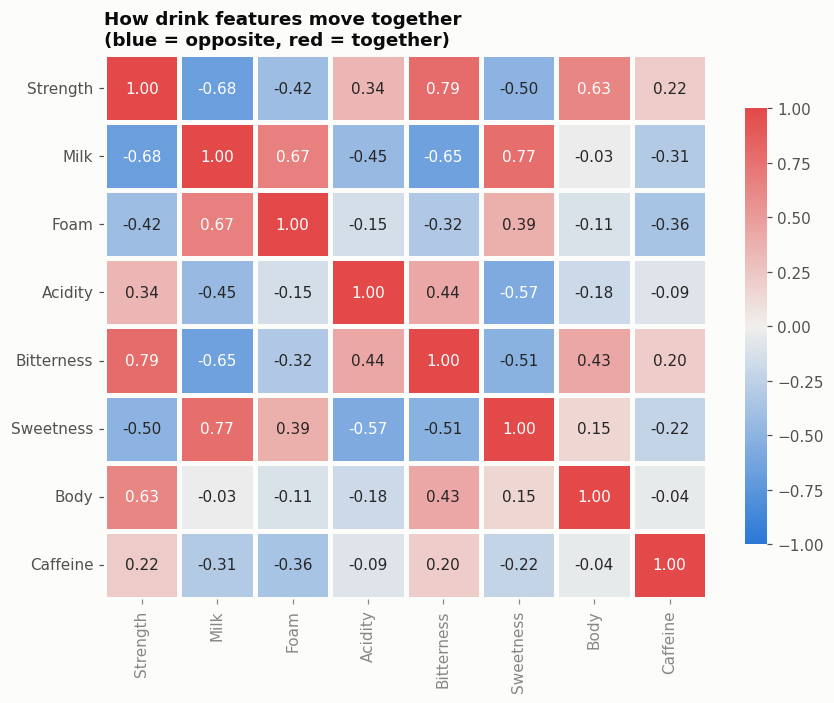

In [4]:
corr = drinks_scaled.rename(columns=FEATURE_LABELS).corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIV_CMAP, center=0, vmin=-1, vmax=1,
            linewidths=2, linecolor=SURFACE, cbar_kws={"shrink": 0.8})
plt.grid(False)
plt.title("How drink features move together\n(blue = opposite, red = together)")
show("feature_correlation")

## Phase 4: Modelling

**4.1 Choosing k.** We fit K-Means for k = 2 to 8 and compare inertia (elbow) and silhouette. With only 27 drinks, large k leaves 3 or 4 drinks per group, so we keep k small.

Silhouette alone picks k = 2, which only splits black from milky drinks. That is too coarse for a menu. **k = 4** scores almost the same as k = 3 and gives groups a barista would recognise (see 4.2), so it is the chosen value. This is a judgement call and is documented here so reviewers can challenge it.

Silhouette by k: {2: 0.39, 3: 0.296, 4: 0.302, 5: 0.28, 6: 0.279, 7: 0.282, 8: 0.307}
Best k by silhouette: 2


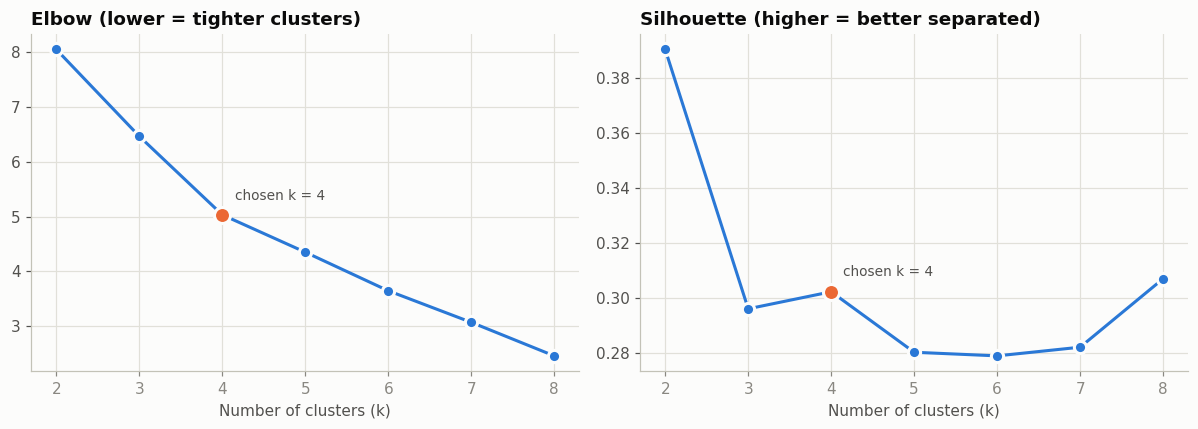

In [5]:
X = drinks_scaled.values
k_values = list(range(2, 9))
inertias, sil_scores = [], []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, km.labels_))

best_k = k_values[int(np.argmax(sil_scores))]
print("Silhouette by k:", {k: round(float(s), 3) for k, s in zip(k_values, sil_scores)})
print("Best k by silhouette:", best_k)

OPTIMAL_K = 4   # chosen for menu-friendly groups (see note above)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, ys, ttl in [(ax[0], inertias, "Elbow (lower = tighter clusters)"),
                   (ax[1], sil_scores, "Silhouette (higher = better separated)")]:
    a.plot(k_values, ys, marker="o", color=BLUE, lw=2, ms=8, mec=SURFACE, mew=2)
    i = k_values.index(OPTIMAL_K)
    a.scatter([OPTIMAL_K], [ys[i]], s=110, color=ORANGE, zorder=4, edgecolor=SURFACE, linewidth=2)
    a.annotate(f"chosen k = {OPTIMAL_K}", (OPTIMAL_K, ys[i]), xytext=(8, 10),
               textcoords="offset points", fontsize=9, color=INK2)
    a.set_title(ttl)
    a.set_xlabel("Number of clusters (k)")
show("elbow_silhouette")

**4.2 Final model.** Fit K-Means with the chosen k and list the members of each cluster.

In [6]:
kmeans = KMeans(n_clusters=OPTIMAL_K, random_state=RANDOM_STATE, n_init=10).fit(X)
drinks["cluster"] = kmeans.labels_
cluster_centers = kmeans.cluster_centers_        # in scaled (0-1) space

print("=== Cluster members ===")
for c in range(OPTIMAL_K):
    members = drinks.loc[drinks["cluster"] == c, "name"].tolist()
    print(f"Cluster {c} ({len(members)}): {', '.join(members)}")

=== Cluster members ===
Cluster 0 (5): Cortado, Piccolo Latte, Flat White, Vietnamese Iced Coffee, Affogato
Cluster 1 (8): Cappuccino, Latte, Iced Latte, Vanilla Latte, Caramel Macchiato, Caffe Mocha, Iced Mocha, Spanish Latte
Cluster 2 (8): Espresso, Doppio, Ristretto, Lungo, Long Black, French Press, Turkish Coffee, Macchiato
Cluster 3 (6): Americano, Drip Coffee, Pour Over, Cold Brew, Iced Americano, Cafe au Lait


**4.3 Reading the clusters.** Each cluster is named automatically by the three features that differ most from the menu average. The heatmap shows every drink, the profile table shows each group's average, and the panels place each group on a 2D map of all 8 features (PCA, used for display only).

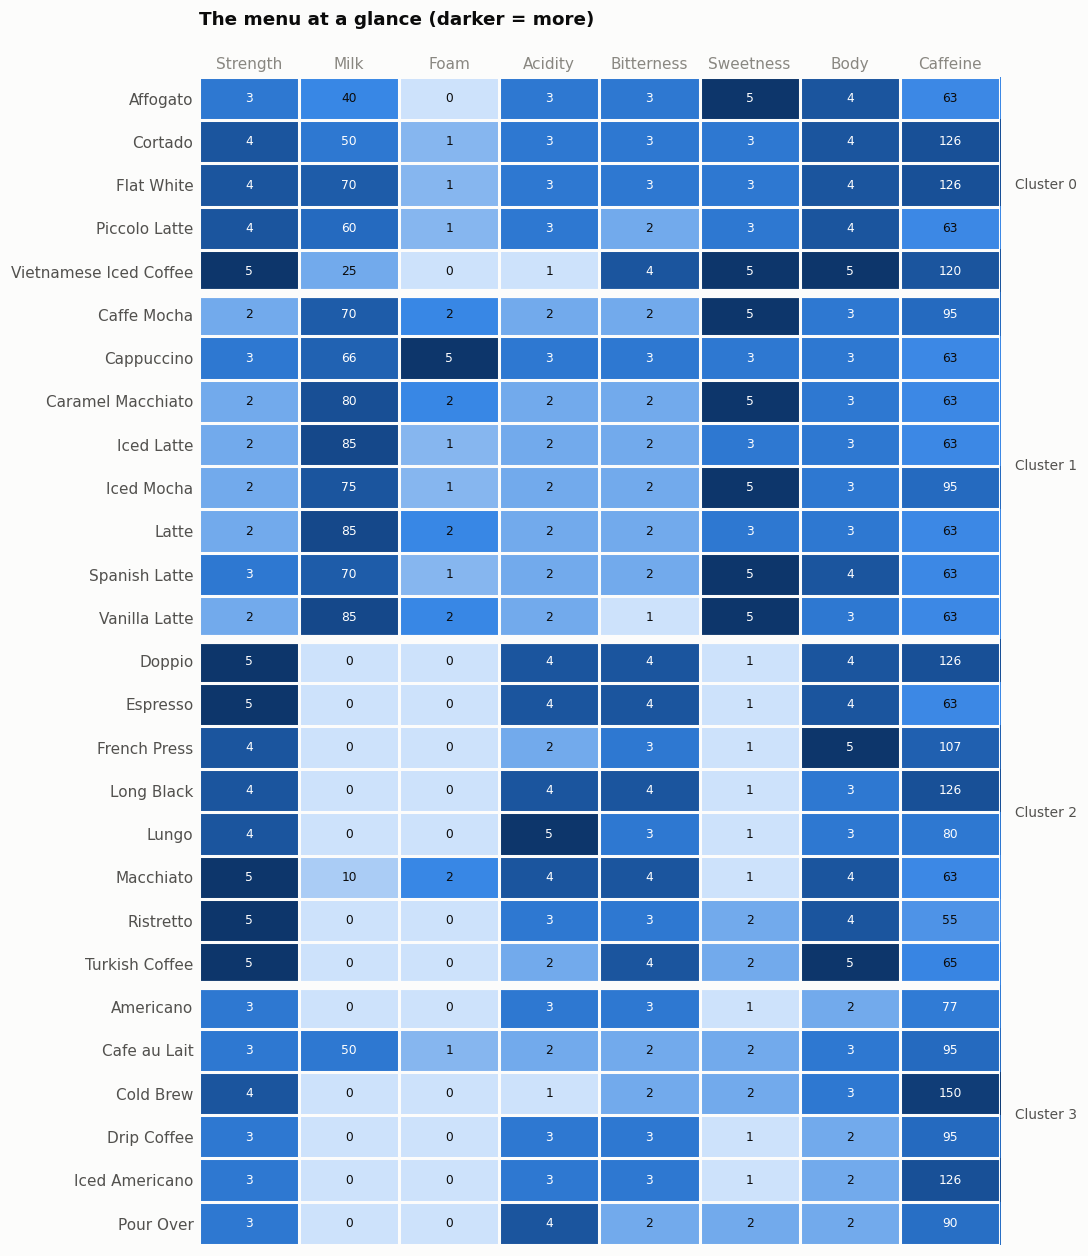

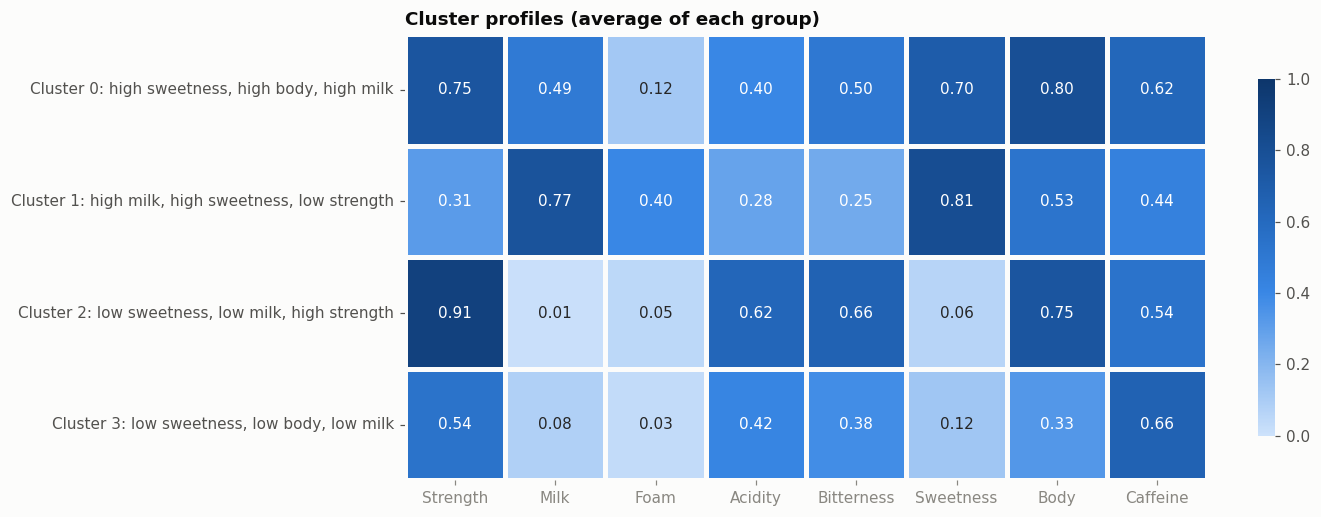

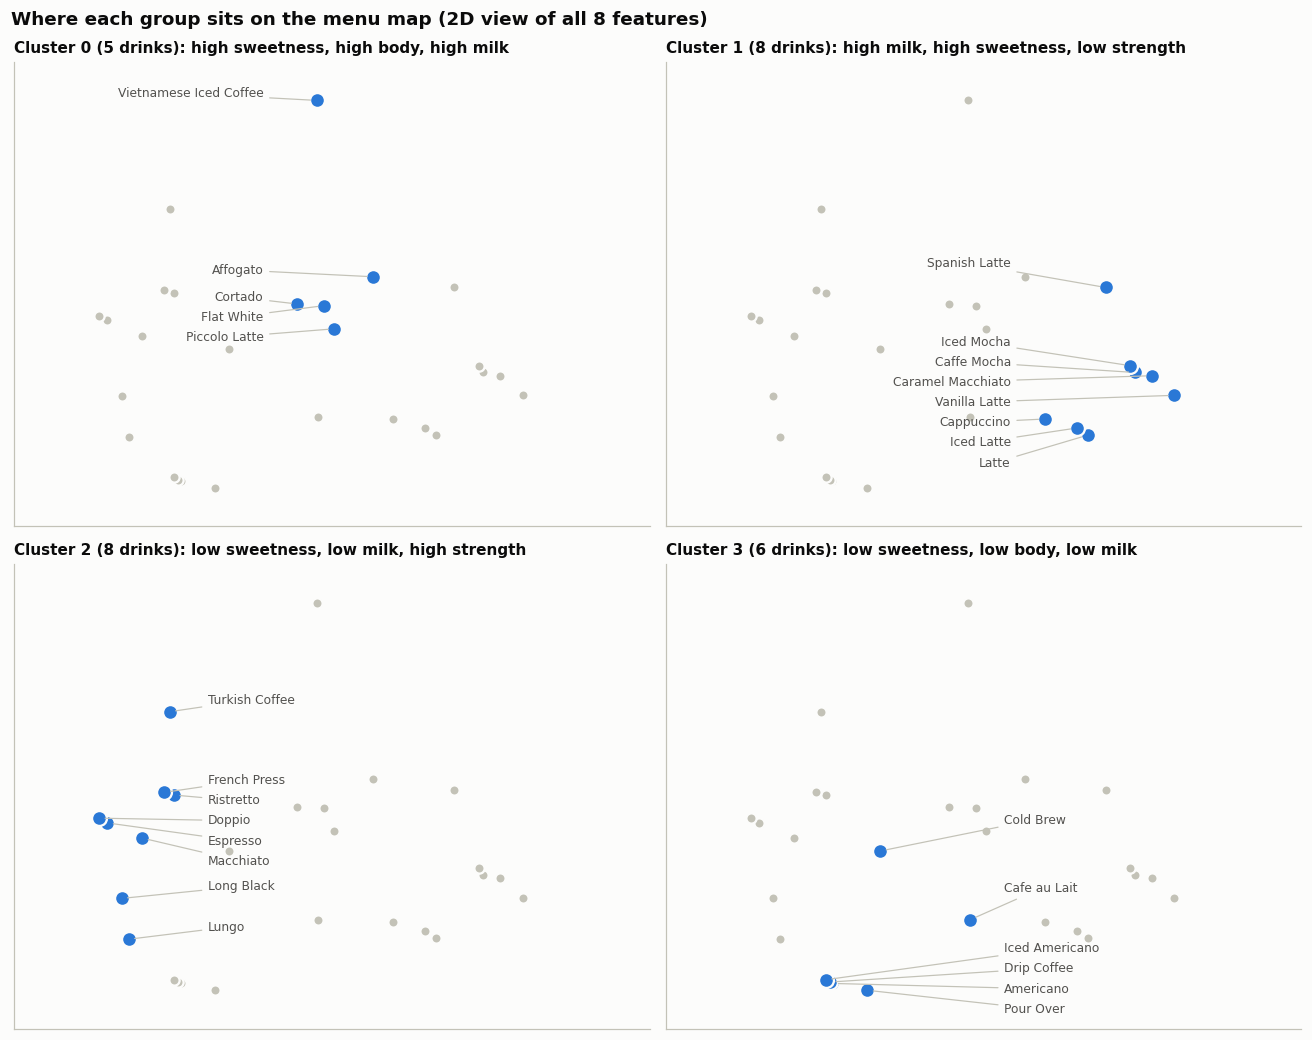

In [7]:
def cluster_label(c):
    """Name a cluster by the three features that set it apart from the menu average."""
    dev = pd.Series(cluster_centers[c], index=drink_features) - drinks_scaled.mean()
    top = dev.abs().sort_values(ascending=False).index[:3]
    return ", ".join(f"{'high' if dev[f] > 0 else 'low'} {FEATURE_LABELS[f].lower()}" for f in top)

def plot_menu_heatmap():
    """Every drink x every feature; darker = more. Numbers are the raw values."""
    order = drinks.sort_values(["cluster", "name"]).index
    data, raw = drinks_scaled.loc[order], drinks.loc[order, drink_features]
    n, m = len(order), len(drink_features)
    fig, ax = plt.subplots(figsize=(10, 0.36 * n + 1.8))
    ax.imshow(data.values, cmap=SEQ_CMAP, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(m))
    ax.set_xticklabels([FEATURE_LABELS[f] for f in drink_features])
    ax.xaxis.tick_top()
    ax.set_yticks(range(n))
    ax.set_yticklabels(drinks.loc[order, "name"])
    ax.grid(False)
    ax.set_xticks(np.arange(-.5, m), minor=True)
    ax.set_yticks(np.arange(-.5, n), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="both", length=0)
    for r in range(n):
        for k in range(m):
            ax.text(k, r, f"{raw.iloc[r, k]:g}", ha="center", va="center",
                    fontsize=8, color=_text_on(data.iloc[r, k]))
    cl = drinks.loc[order, "cluster"].values
    for r in range(1, n):
        if cl[r] != cl[r - 1]:
            ax.axhline(r - 0.5, color=SURFACE, linewidth=6)
    for c in np.unique(cl):
        rows = np.where(cl == c)[0]
        ax.text(m - 0.35, rows.mean(), f"Cluster {c}", va="center", fontsize=9,
                color=INK2, clip_on=False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title("The menu at a glance (darker = more)", pad=34)
    show("menu_heatmap")

def plot_cluster_profiles():
    """What each cluster is like, on the 0-1 scale."""
    centers = pd.DataFrame(cluster_centers, columns=[FEATURE_LABELS[f] for f in drink_features])
    centers.index = [f"Cluster {c}: {cluster_label(c)}" for c in range(len(centers))]
    plt.figure(figsize=(13, 0.8 * len(centers) + 1.6))
    sns.heatmap(centers, annot=True, fmt=".2f", cmap=SEQ_CMAP, vmin=0, vmax=1,
                linewidths=2, linecolor=SURFACE, cbar_kws={"shrink": 0.8})
    plt.grid(False)
    plt.xticks(rotation=0)
    plt.title("Cluster profiles (average of each group)")
    show("cluster_profiles")

def _spread_labels(ax, pts, names, xr, yr, ylim, x_centre):
    """Aligned label column beside the group so near-identical drinks stay readable."""
    order = np.argsort(-pts[:, 1])
    ys = pts[order, 1].astype(float)
    gap = 0.052 * yr
    for j in range(1, len(ys)):
        ys[j] = min(ys[j], ys[j - 1] - gap)
    ys += pts[order, 1].mean() - ys.mean()
    lo, hi = ylim[0] + gap, ylim[1] - gap
    if ys.max() > hi:
        ys -= ys.max() - hi
    if ys.min() < lo:
        ys += lo - ys.min()
    on_right = pts[:, 0].mean() <= x_centre
    lx = pts[:, 0].max() + 0.08 * xr if on_right else pts[:, 0].min() - 0.08 * xr
    for (px, py), ly, name in zip(pts[order], ys, np.array(names)[order]):
        ax.annotate(name, (px, py), xytext=(lx, ly), fontsize=8, color=INK2,
                    ha="left" if on_right else "right", va="center",
                    arrowprops=dict(arrowstyle="-", color=AXIS, linewidth=0.8,
                                    shrinkA=2, shrinkB=4))

def plot_cluster_panels():
    """One small map per cluster: its drinks in blue and labelled, the rest in grey."""
    coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
    xr, yr = np.ptp(coords[:, 0]), np.ptp(coords[:, 1])
    n, cols = OPTIMAL_K, 2
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(12, 4.8 * rows), sharex=True, sharey=True)
    flat = np.ravel(axes)
    for c, ax in zip(range(n), flat):
        mine = (drinks["cluster"] == c).values
        ax.scatter(coords[~mine, 0], coords[~mine, 1], s=45, color=DIM,
                   edgecolor=SURFACE, linewidth=1.5, zorder=2)
        ax.scatter(coords[mine, 0], coords[mine, 1], s=95, color=BLUE,
                   edgecolor=SURFACE, linewidth=1.5, zorder=3)
        ylim = (coords[:, 1].min() - 0.1 * yr, coords[:, 1].max() + 0.1 * yr)
        ax.set_xlim(coords[:, 0].min() - 0.2 * xr, coords[:, 0].max() + 0.3 * xr)
        ax.set_ylim(*ylim)
        _spread_labels(ax, coords[mine], drinks.loc[mine, "name"].tolist(), xr, yr,
                       ylim, coords[:, 0].mean())
        ax.set_title(f"Cluster {c} ({mine.sum()} drinks): {cluster_label(c)}", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for ax in flat[n:]:
        ax.axis("off")
    fig.suptitle("Where each group sits on the menu map (2D view of all 8 features)",
                 x=0.01, ha="left", fontsize=12, fontweight="bold")
    show("cluster_panels")

plot_menu_heatmap()
plot_cluster_profiles()
plot_cluster_panels()

**4.4 The recommender.** Two modes share one scoring rule (`match = 1 - weighted RMS distance`):

- `recommend_drinks(prefs)`: rank the menu against the tastes a customer states. Omitted features are ignored, and `weights` lets one feature matter more.
- `similar_drinks(name)`: "I liked my Flat White, what else?"

Filters run before ranking. Ties are common because menu values are whole numbers, so scores are rounded to 6 decimals and ties are broken by `drink_id`. This keeps results identical between runs and between Python and the app.

In [8]:
def _apply_filters(frame, temperature=None, max_caffeine=None, no_milk=False,
                   categories=None):
    mask = pd.Series(True, index=frame.index)
    if temperature:
        # 'hot-cold' drinks (e.g. Affogato) match either request
        mask &= frame["temperature"].isin([temperature, "hot-cold"])
    if max_caffeine is not None:
        mask &= frame["caffeine_mg"] <= max_caffeine
    if no_milk:
        mask &= frame["milk_pct"] == 0
    if categories:
        mask &= frame["category"].isin(categories)
    return mask

def _weighted_distance(scaled_frame, target, weights, cols):
    """Weighted RMS difference on the 0-1 scale. 0 = identical."""
    w = pd.Series({f: (weights or {}).get(f, 1.0) for f in cols})
    diff = scaled_frame[cols] - target[cols]
    return np.sqrt((w * diff ** 2).sum(axis=1) / w.sum())

def _rank(frame):
    """Best match first; exact ties are broken by drink_id so output is deterministic."""
    return frame.sort_values(["similarity", "drink_id"], ascending=[False, True])

def recommend_drinks(prefs, weights=None, top_n=5, within_cluster=False, **filters):
    """
    prefs: raw drink scales, e.g. {'strength': 3, 'milk_pct': 70, 'sweetness': 4}
           (strength/acidity/bitterness/sweetness/body 1-5, foam 0-5,
            milk_pct 0-100, caffeine_mg 0-160). Omitted features are ignored.
    weights: optional {'sweetness': 2.0} to make a feature matter more.
    within_cluster: restrict to the cluster whose centre is nearest the prefs
                    (falls back to the full menu if that leaves fewer than top_n).
    filters: temperature='hot'|'iced', max_caffeine=int, no_milk=bool, categories=[...]
    """
    unknown = set(prefs) - set(drink_features)
    if unknown:
        raise ValueError(f"Unknown preference(s): {sorted(unknown)}")
    given = [f for f in drink_features if f in prefs]
    if not given:
        raise ValueError("Give at least one drink preference.")

    user = scale_drink_values(pd.DataFrame([{f: prefs[f] for f in given}])).iloc[0]

    out = drinks.copy()
    out["distance"] = _weighted_distance(drinks_scaled, user, weights, given)
    out["similarity"] = (1 - out["distance"]).round(6)

    mask = _apply_filters(out, **filters)
    if within_cluster:
        idx = [drink_features.index(f) for f in given]
        centers = pd.DataFrame(cluster_centers[:, idx], columns=given)
        w = np.array([(weights or {}).get(f, 1.0) for f in given])
        d = np.sqrt((w * (centers - user[given]) ** 2).sum(axis=1) / w.sum())
        nearest = int(d.values.argmin())
        in_cluster = mask & (out["cluster"] == nearest)
        if in_cluster.sum() >= top_n:
            mask = in_cluster

    out = _rank(out[mask])
    return out[["name", "category", "temperature"] + given + ["similarity"]].head(top_n)

def similar_drinks(drink_name, weights=None, top_n=5, **filters):
    """Drinks closest to an existing menu item (e.g. 'I liked my Flat White')."""
    match = drinks.index[drinks["name"].str.lower() == drink_name.lower()]
    if len(match) == 0:
        close = drinks["name"][drinks["name"].str.contains(drink_name, case=False, regex=False)].tolist()
        raise ValueError(f"'{drink_name}' not on the menu. Did you mean: {close or drinks['name'].tolist()}")
    i = match[0]

    out = drinks.copy()
    out["distance"] = _weighted_distance(drinks_scaled, drinks_scaled.loc[i],
                                         weights, drink_features)
    out["similarity"] = (1 - out["distance"]).round(6)

    mask = _apply_filters(out, **filters) & (out.index != i)   # exclude itself
    out = _rank(out[mask])
    return out[["name", "category", "temperature", "flavor_notes", "similarity"]].head(top_n)

**4.5 Display helpers.** Ranked bars show the top picks. A second chart sets the customer's request beside the top drink, feature by feature, to explain *why* it was picked.

In [9]:
def plot_recommendations(picks, title, filename="recommendations"):
    """Ranked bars: best match on top."""
    p = picks.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(p) + 1.4))
    ax.barh(p["name"], p["similarity"], height=0.55, color=BLUE)
    for y, v in enumerate(p["similarity"]):
        ax.text(v + 0.015, y, f"{v:.2f}", va="center", fontsize=9, color=INK2)
    ax.set_xlim(0, 1.12)
    ax.set_xlabel("Match (1.00 = identical to the request)")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    show(filename)

def plot_request_vs_drink(prefs, drink_name, filename="request_vs_drink"):
    """Why this drink? The request next to the drink, feature by feature."""
    feats = [f for f in drink_features if f in prefs]
    req = scale_drink_values(pd.DataFrame([{f: prefs[f] for f in feats}])).iloc[0]
    row = drinks_scaled.loc[drinks["name"] == drink_name, feats].iloc[0]
    y, h = np.arange(len(feats)), 0.34
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(feats) + 1.8))
    ax.barh(y - h / 2, req.values, height=h, color=BLUE, edgecolor=SURFACE,
            linewidth=1.5, label="Your request")
    ax.barh(y + h / 2, row.values, height=h, color=ORANGE, edgecolor=SURFACE,
            linewidth=1.5, label=drink_name)
    ax.set_yticks(y)
    ax.set_yticklabels([FEATURE_LABELS[f] for f in feats])
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("Scaled 0-1 (low to high)")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.legend(frameon=False, ncol=2, loc="upper left", bbox_to_anchor=(0, -0.2))
    ax.set_title(f"Your request vs {drink_name}")
    show(filename)

def recommend(prefs, top_n=3, plot=True, **kwargs):
    """Print and (optionally) plot the top picks for a customer request."""
    picks = recommend_drinks(prefs, top_n=top_n, **kwargs)
    if picks.empty:
        print("No drinks match those filters.")
        return picks
    notes = drinks.set_index("name")["flavor_notes"]
    for _, r in picks.iterrows():
        print(f"{r['name']:<24} match {r['similarity']:.2f}   {notes[r['name']]}")
    if plot:
        plot_recommendations(picks, "Top picks for your request")
        plot_request_vs_drink(prefs, picks.iloc[0]["name"])
    return picks

## Phase 5: Evaluation

There is no ground truth (no record of what customers *should* have been served), so we test expected behaviour instead.

**5.1 Worked examples.** Realistic customer requests, including filters and the "similar to" mode.

--- Sweet, milky, mild, hot ---
Caramel Macchiato        match 1.00   layered, sweet caramel, vanilla
Vanilla Latte            match 0.97   sweet vanilla, creamy, dessert-like
Caffe Mocha              match 0.95   chocolate and espresso, rich, sweet


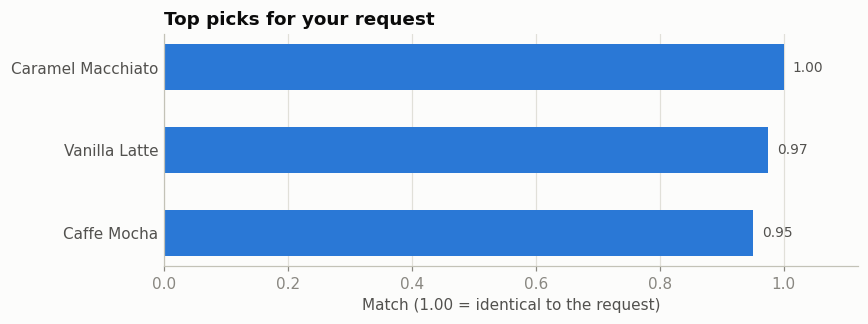

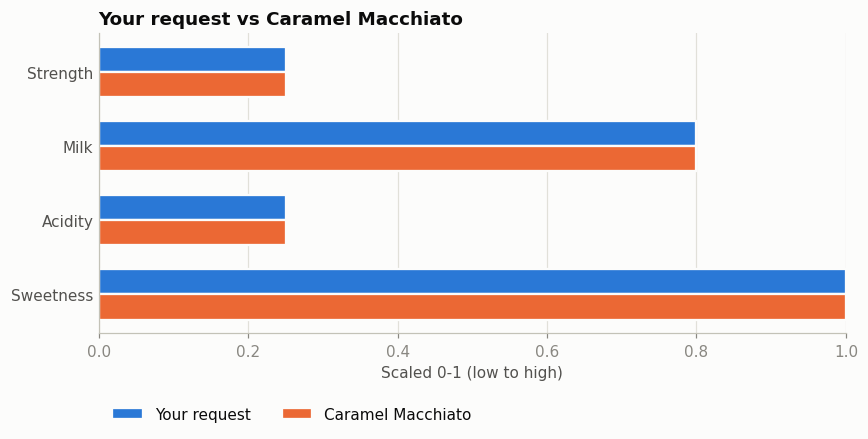


--- Strong black, no milk ---
Espresso                 match 1.00   intense, caramelised, lingering finish
Doppio                   match 1.00   intense, heavy, bittersweet
Ristretto                match 0.88   concentrated, sweeter and less bitter than espresso

--- Dairy-free, iced, bright, low caffeine ---
Iced Americano           match 0.80   refreshing, crisp, roasty

--- Similar to Flat White ---
         name  category temperature                             flavor_notes  similarity
      Cortado  espresso         hot balanced, espresso softened by warm milk       0.929
Piccolo Latte  espresso         hot              small, concentrated, creamy       0.831
 Cafe au Lait      milk         hot    drip coffee with steamed milk, mellow       0.779
Spanish Latte flavoured         hot        condensed milk, very sweet, silky       0.728


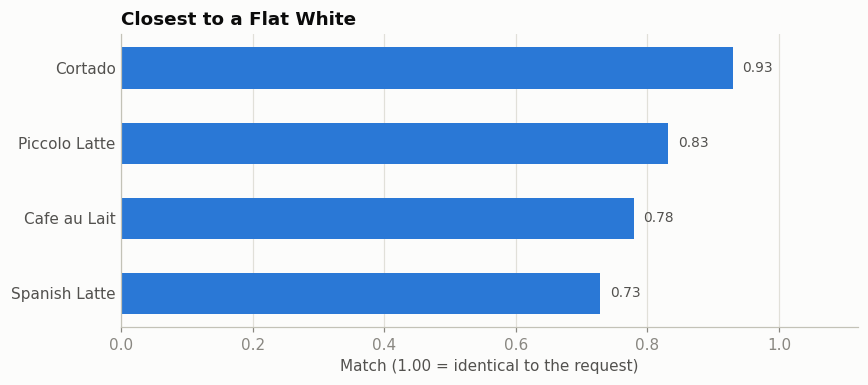


--- Similar to Iced Latte, but hot ---
             name  category temperature                          flavor_notes  similarity
            Latte      milk         hot    creamy, milky, mild coffee flavour       0.929
     Cafe au Lait      milk         hot drip coffee with steamed milk, mellow       0.810
Caramel Macchiato flavoured         hot       layered, sweet caramel, vanilla       0.809
    Vanilla Latte flavoured         hot   sweet vanilla, creamy, dessert-like       0.790


In [10]:
print("--- Sweet, milky, mild, hot ---")
recommend({"strength": 2, "milk_pct": 80, "sweetness": 5, "acidity": 2},
          temperature="hot")

print("\n--- Strong black, no milk ---")
recommend({"strength": 5, "milk_pct": 0, "sweetness": 1, "body": 4}, no_milk=True,
          plot=False)

print("\n--- Dairy-free, iced, bright, low caffeine ---")
recommend({"strength": 3, "acidity": 4, "sweetness": 2},
          temperature="iced", no_milk=True, max_caffeine=130, plot=False)

print("\n--- Similar to Flat White ---")
sim = similar_drinks("Flat White", top_n=4)
print(sim.round(3).to_string(index=False))
plot_recommendations(sim, "Closest to a Flat White", "similar_flat_white")

print("\n--- Similar to Iced Latte, but hot ---")
print(similar_drinks("Iced Latte", temperature="hot", top_n=4).round(3).to_string(index=False))

**5.2 Sanity checks.** For each request, the top 3 drinks must come from the categories we expect. Then we check whether narrowing to the nearest cluster changes the answer.

In [11]:
checks = [
    ("sweet milky mild",
     {"strength": 2, "milk_pct": 80, "sweetness": 5},
     {"flavoured", "milk"}),
    ("strong, no milk, bitter",
     {"strength": 5, "milk_pct": 0, "bitterness": 4, "sweetness": 1},
     {"espresso", "black"}),
    ("foamy, medium milk (foam weighted x3)",
     {"strength": 3, "milk_pct": 66, "foam_level": 5},
     {"milk", "flavoured"},
     {"foam_level": 3}),
]
print("=== Sanity checks (top-3 categories should fall in expected set) ===")
results = []
for label, prefs, expected, *opt in checks:
    top = recommend_drinks(prefs, weights=opt[0] if opt else None, top_n=3)
    ok = set(top["category"]) <= expected
    results.append(ok)
    print(f"[{'PASS' if ok else 'CHECK'}] {label}: {top['name'].tolist()}")
print(f"\n{sum(results)}/{len(results)} sanity checks passed")

# Does restricting to the nearest cluster change the answer vs plain ranking?
test = {"strength": 3, "milk_pct": 70, "foam_level": 3, "acidity": 2,
        "sweetness": 4, "caffeine_mg": 100}
plain = recommend_drinks(test, top_n=5)["name"].tolist()
clustered = recommend_drinks(test, top_n=5, within_cluster=True)["name"].tolist()
print("\nPlain ranking:   ", plain)
print("Within cluster:  ", clustered)
print("Overlap:", len(set(plain) & set(clustered)), "/ 5")

=== Sanity checks (top-3 categories should fall in expected set) ===
[PASS] sweet milky mild: ['Caramel Macchiato', 'Vanilla Latte', 'Iced Mocha']
[PASS] strong, no milk, bitter: ['Espresso', 'Doppio', 'Macchiato']
[PASS] foamy, medium milk (foam weighted x3): ['Cappuccino', 'Caffe Mocha', 'Caramel Macchiato']

3/3 sanity checks passed

Plain ranking:    ['Caffe Mocha', 'Caramel Macchiato', 'Latte', 'Vanilla Latte', 'Spanish Latte']
Within cluster:   ['Caffe Mocha', 'Caramel Macchiato', 'Latte', 'Vanilla Latte', 'Spanish Latte']
Overlap: 5 / 5


**5.3 Robustness tests.** These guard the behaviour the app depends on:

- **Stability:** do the clusters stay the same under different random starts? (Adjusted Rand index of 1.0 means identical groups.)
- **Input handling:** bad input fails clearly, over-strict filters return an empty result instead of crashing, and out-of-range values are clipped.
- **Exact match:** a drink's own profile returns that drink first.

In [12]:
# Stability across random starts (same k, different seeds)
aris = [adjusted_rand_score(kmeans.labels_,
                            KMeans(n_clusters=OPTIMAL_K, random_state=s, n_init=10).fit(X).labels_)
        for s in range(20)]
print(f"Cluster stability over 20 seeds: min ARI = {min(aris):.2f}, mean ARI = {np.mean(aris):.2f}")

# Input handling
def raises(fn, exc):
    try:
        fn()
    except exc:
        return True
    return False

assert raises(lambda: recommend_drinks({"sweetnes": 3}), ValueError), "typo'd feature must raise"
assert raises(lambda: recommend_drinks({}), ValueError), "empty prefs must raise"
assert raises(lambda: similar_drinks("Flat Whte"), ValueError), "unknown drink must raise"
assert recommend_drinks({"strength": 5}, no_milk=True, max_caffeine=10).empty, "impossible filters -> empty"
assert recommend_drinks({"strength": 99}, top_n=1).iloc[0]["strength"] == 5, "out-of-range input is clipped"

# Exact match: each drink's own full profile must rank itself first (ties allowed)
misses = []
for _, r in drinks.iterrows():
    top = recommend_drinks({f: r[f] for f in drink_features}, top_n=1)
    if top.iloc[0]["similarity"] < 1.0:
        misses.append(r["name"])
assert not misses, misses
print("All robustness tests passed.")

Cluster stability over 20 seeds: min ARI = 0.68, mean ARI = 0.89
All robustness tests passed.


## Phase 6: Deployment (export for the mobile app)

The app does not run Python. It loads `model.json`, which holds the cluster labels and centres, and every drink's raw feature values. The Kotlin side repeats the same steps: scale with the fixed bounds, compute the distance and rank. The export reuses the model fitted above (no second fit), so the file always matches what was evaluated.

The JSON structure is unchanged from the version the app already reads. The bounds are **not** in the file, so they must match `BOUNDS` in `Recommender.kt`. The parity check below proves the file alone reproduces the Python results.

In [13]:
labels = [cluster_label(c) for c in range(OPTIMAL_K)]

payload = {
    "source": DRINKS_PATH.name,
    "labels": labels,
    "centers": kmeans.cluster_centers_.tolist(),
    "drinks": [{
        "name": r["name"], "category": str(r["category"]), "temperature": str(r["temperature"]),
        "flavor_notes": "" if pd.isna(r.get("flavor_notes")) else str(r["flavor_notes"]),
        "cluster": int(r["cluster"]), "raw": [float(r[f]) for f in drink_features],
    } for _, r in drinks.iterrows()],
}
MODEL_PATH = MODEL_PATH.resolve()
MODEL_PATH.write_text(json.dumps(payload, indent=1), encoding="utf-8")
print(f"Wrote {MODEL_PATH}  ({len(drinks)} drinks, k={OPTIMAL_K})\n")

summary = pd.DataFrame({
    "label": labels,
    "size": [(drinks.cluster == c).sum() for c in range(OPTIMAL_K)],
    "drinks": [", ".join(drinks.loc[drinks.cluster == c, "name"]) for c in range(OPTIMAL_K)],
})
summary.index.name = "group"
display(summary)

Wrote /content/model.json  (27 drinks, k=4)



,label,size,drinks
group,,,
0,"high sweetness, high body, high milk",5,"Cortado, Piccolo Latte, Flat White, Vietnamese..."
1,"high milk, high sweetness, low strength",8,"Cappuccino, Latte, Iced Latte, Vanilla Latte, ..."
2,"low sweetness, low milk, high strength",8,"Espresso, Doppio, Ristretto, Lungo, Long Black..."
3,"low sweetness, low body, low milk",6,"Americano, Drip Coffee, Pour Over, Cold Brew, ..."


**6.1 Parity check.** A separate, minimal re-implementation reads *only* `model.json` (as the app will) and must give the same ranking and scores as the notebook's recommender. If a bound, feature order or tie rule drifts between the two, this fails.

In [14]:
# Independent "app-side" scorer: uses only model.json and the fixed bounds
m = json.loads(MODEL_PATH.read_text(encoding="utf-8"))
raw = np.array([d["raw"] for d in m["drinks"]])
names = [d["name"] for d in m["drinks"]]
lo = np.array([drink_bounds[f][0] for f in drink_features], dtype=float)
hi = np.array([drink_bounds[f][1] for f in drink_features], dtype=float)
S = np.clip((raw - lo) / (hi - lo), 0, 1)

def app_rank(prefs, top_n=3):
    idx = [drink_features.index(f) for f in drink_features if f in prefs]
    u = np.clip((np.array([prefs[drink_features[i]] for i in idx]) - lo[idx]) / (hi[idx] - lo[idx]), 0, 1)
    sim = np.round(1 - np.sqrt(((S[:, idx] - u) ** 2).mean(axis=1)), 6)
    order = np.lexsort((np.arange(len(sim)), -sim))[:top_n]     # score desc, then menu order
    return [names[i] for i in order], sim[order]

parity_requests = [
    {"strength": 2, "milk_pct": 80, "sweetness": 5, "acidity": 2},
    {"strength": 5, "milk_pct": 0, "sweetness": 1, "body": 4},
    {"strength": 3, "acidity": 4, "sweetness": 2},
    {"strength": 3, "milk_pct": 66, "foam_level": 5},
    {"caffeine_mg": 150, "sweetness": 1},
]
for p in parity_requests:
    py = recommend_drinks(p, top_n=3)
    app_names, app_scores = app_rank(p, top_n=3)
    assert py["name"].tolist() == app_names, (p, py["name"].tolist(), app_names)
    assert np.allclose(py["similarity"].values, app_scores), p
print(f"Parity check passed on {len(parity_requests)} requests: model.json reproduces the notebook's rankings.")

Parity check passed on 5 requests: model.json reproduces the notebook's rankings.


## Limitations and next steps

- **Small menu (27 drinks).** Clusters are readable but not statistically strong (silhouette about 0.3), and a few borderline drinks can switch group under other random starts (see 5.3). The exported model fixes `random_state=42`, so the app always sees the same groups. Treat clusters as a menu-grouping aid: the ranking itself does not depend on them.
- **Menu values are expert-assigned whole numbers,** so tied scores are common. Ties are broken by menu order, which is stable but arbitrary.
- **Taste input is self-reported.** Customers may rate "strong" differently from the menu scale. This is a risk to test with real customers.
- **No ground truth yet.** Satisfaction against barista advice is tested after deployment (success criteria 1.5).
- **Next:** compare K-Means with other clustering models, and learn feature weights from customer feedback once the app is live.

## References

- Iyengar, S. S., & Lepper, M. R. (2000). When choice is demotivating: Can one desire too much of a good thing? *Journal of Personality and Social Psychology, 79*(6), 995-1006.
- Barista survey response, Nairobi (2026, September 21). Google Forms. [Primary source]
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.